In [3]:
import jax
jax.config.update("jax_enable_x64", True)

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

from scipy.special import comb

import sys
sys.path.insert(0, '..')

from mctdhf import *
from utils import *
import pint

In [79]:
d = np.load("optimize_qubit_params_trajectory.npz")

In [80]:
print(d.files)
print(d['best_x'])
alphas = d['best_x'][:4]
betas = d['best_x'][4:]

['xs', 'losses', 'min_fids', 'walls', 'oob', 'best_x', 'best_loss', 'solver_x', 'solver_fun', 'solver_flag', 'solver_msg', 'wall_total', 'configs', 'fid_xs', 'fidelities', 'matched_idx', 'energies']
[ 5.          9.3808011  12.00261519 15.          0.17781312  0.22486074
  0.32610633  0.26059372]


# Define units

In [81]:
ureg = pint.UnitRegistry()

typical_freq = 10 * ureg.GHz

omega = 2*np.pi*typical_freq
energy_to_frequency = 1 / ureg.planck_constant
energy_unit = ureg.hbar * omega
length_unit = np.sqrt(ureg.hbar / (ureg.m_e * omega))

KAPPA = (
    (length_unit * ureg.m_e * ureg.e**2 / (4 * ureg.pi * ureg.epsilon_0 * ureg.hbar**2))
    .to(ureg.dimensionless)
    .magnitude
)


def anharm_pot(a, b, center):
    return (
        lambda x: 0.5 * a**2 * (x - center) ** 2 + ((b * a**2) / 3) * (x - center) ** 4
    )


def coulomb(x_1, x_2):
    return KAPPA / np.sqrt((x_1 - x_2) ** 2)

# Set up Sine-DVR basis

In [82]:
# alphas = [7, 9, 11, 13]
# betas = [0.2, 0.2, 0.2, 0.2]

alphas = (np.array(alphas)*ureg.GHz / energy_to_frequency / energy_unit).to(ureg.dimensionless)
betas = (np.array(betas)*ureg.GHz / energy_to_frequency / energy_unit).to(ureg.dimensionless)

num_wells = 4
num_dvr = 64

well_centers = (np.array([-1.5, -0.5, 0.5, 1.5])*ureg.mum / length_unit).to(ureg.dimensionless)
well_widths = (np.array([1, 1, 1, 1])*ureg.mum / length_unit).to(ureg.dimensionless)

np.testing.assert_equal(len(well_centers), num_wells)
np.testing.assert_equal(len(well_widths), num_wells)
np.testing.assert_equal(len(alphas), num_wells)
np.testing.assert_equal(len(betas), num_wells)

potentials = [anharm_pot(a, b, center) for a, b, center in zip(alphas, betas, well_centers)]

dvr_bases = []
for center, width in zip(well_centers, well_widths):
    dvr = SineDVR(
        x_min=center - 0.5*width,
        x_max=center + 0.5*width,
        num_points=num_dvr,
    )
    dvr_bases.append(dvr)

## Set up single-particle problem and plot the lowest eigenstates

/home/oskar/projects/n-species-mctdh/test/venv/lib/python3.14/site-packages/jax/_src/numpy/array_constructors.py:262: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  out = np.asarray(object, dtype=dtype)
/tmp/ipykernel_207362/3758029634.py:14: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  eigvals, eigvecs = np.linalg.eigh(np.asarray(h))
/tmp/ipykernel_207362/3758029634.py:20: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  V = np.asarray(pot(grid))
/home/oskar/projects/n-species-mctdh/test/venv/lib/python3.14/site-packages/matplotlib/cbook.py:1355: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  return np.asarray(x, float)
/home/oskar/projects/n-species-mctdh/test/venv/lib/python3.14/site-packages/numpy/ma/core.py:2896: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  _data = np.arra

Well 1 lowest 4 eigenvalues: [ 2.5428  7.7095 13.0322 18.4993]
Well 1 transition frequencies (GHz): [ 5.1667 10.4895 15.9566]
Well 2 lowest 4 eigenvalues: [ 4.7451 14.341  24.1419 34.1367]
Well 2 transition frequencies (GHz): [ 9.5958 19.3967 29.3915]
Well 3 lowest 4 eigenvalues: [ 6.0804 18.3932 31.0001 43.8834]
Well 3 transition frequencies (GHz): [12.3127 24.9196 37.8029]
Well 4 lowest 4 eigenvalues: [ 7.5639 22.816  38.3115 54.0402]
Well 4 transition frequencies (GHz): [15.2521 30.7476 46.4763]


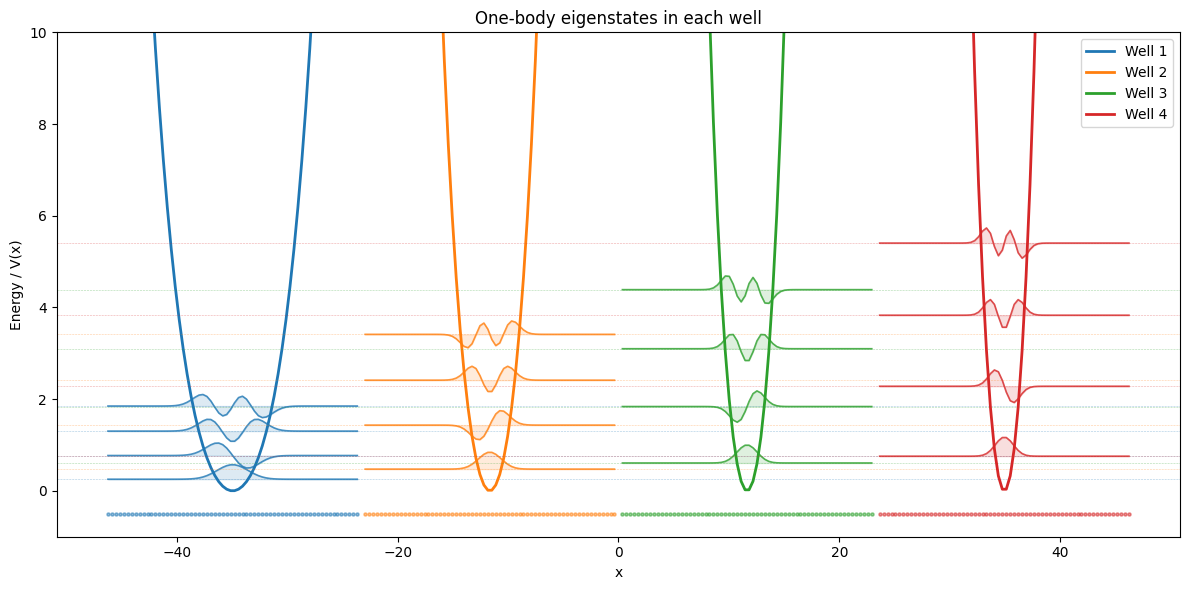

In [83]:
num_eigenstates = 4
wf_scale = 0.5  # visual amplitude scaling

fig, ax = plt.subplots(figsize=(12, 6))

h_list = []

for i, (dvr, pot) in enumerate(zip(dvr_bases, potentials)):
    grid = dvr.get_grid()
    h = dvr.get_h(potential=pot)
    h_list.append(jnp.array(h, dtype=jnp.float32))

    # Diagonalize in the DVR basis (h is symmetric)
    eigvals, eigvecs = np.linalg.eigh(np.asarray(h))

    # DVR eigenvectors normalized with sqrt(dx) so ψ(x_i) = c_i / sqrt(dx)
    psi_dvr = eigvecs / np.sqrt(dvr.dx)

    # Plot the potential
    V = np.asarray(pot(grid))
    ax.plot(grid, V, f"C{i}", lw=2, label=f"Well {i+1}")
    ax.scatter(grid, np.zeros_like(grid) - 0.5, color = f"C{i}", s=5, alpha=0.5)

    # Overlay wavefunctions offset by their eigenvalues
    for n in range(num_eigenstates):
        E_n = eigvals[n]
        wf = psi_dvr[:, n]
        # Fix sign so peak is positive
        if wf[np.argmax(np.abs(wf))] < 0:
            wf = -wf
        ax.axhline(E_n, color=f"C{i}", ls="--", lw=0.4, alpha=0.4)
        ax.plot(grid, E_n + wf_scale * wf, f"C{i}", lw=1.2, alpha=0.8)
        ax.fill_between(grid, E_n, E_n + wf_scale * wf, color=f"C{i}", alpha=0.15)

    print(f"Well {i+1} lowest {num_eigenstates} eigenvalues:",
          np.array2string(eigvals[:num_eigenstates]*(energy_unit*energy_to_frequency).to(ureg.GHz).magnitude, precision=4))
    print(f"Well {i+1} transition frequencies (GHz):",
          np.array2string((eigvals[1:num_eigenstates] - eigvals[0])*(energy_unit*energy_to_frequency).to(ureg.GHz).magnitude, precision=4))

ax.set_xlabel("x")
ax.set_ylabel("Energy / V(x)")
ax.set_title("One-body eigenstates in each well")
ax.legend(loc="upper right")
ax.set_ylim(-1, 10)
plt.tight_layout()
plt.show()

## Compute inter-species Coulomb interaction elements

Since the particles are in separate wells, we only have inter-species interactions.
For DVR, the interaction matrix is 2D: `g[i,j] = V(x_i, x_j) * dx1 * dx2`

In [84]:
# Compute g_dict for all species pairs
# For DVR, g is 2D: g[i,j] = V(x_i, x_j) * dx_i * dx_j
g_dict = {}

for s1 in range(num_wells):
    for s2 in range(s1, num_wells):  # Only upper triangle, transpose handles rest
        if s1 != s2:
            # Same species (intra-well interaction)
            #g = dvr_bases[s1].get_g(coulomb)
        #else:
            # Different species (inter-well interaction)
            g = dvr_bases[s1].get_g_cross_species(dvr_bases[s2], coulomb)
            g_dict[(s1, s2)] = jnp.array(g, jnp.float32)

# Set up MCTDH calculation

In [85]:
print("Number of single excitation states:", comb(num_wells, 1, exact=True, repetition=True))
print("Number of double excitation states:", comb(num_wells, 2, exact=True, repetition=True))
print("Number of triple excitation states:", comb(num_wells, 3, exact=True, repetition=True))
print("Number of quadruple excitation states:", comb(num_wells, 4, exact=True, repetition=True))
print("Total number of states up to quadruple excitations:", comb(num_wells+1, 4, exact=True, repetition=True))

Number of single excitation states: 4
Number of double excitation states: 10
Number of triple excitation states: 20
Number of quadruple excitation states: 35
Total number of states up to quadruple excitations: 70


In [86]:
# MCTDHF parameters
num_particles = [1]*num_wells  # One particle per species
num_mctdhf_orbitals = [4]*num_wells  # MCTDHF orbitals per species
num_spatial_orbitals = [num_dvr]*num_wells  # DVR grid points
num_states = 50

# Create MCTDHF object (use DVR variant for 2D interaction matrices)
mctdhf = MCTDHF_n_species_DVR(
    h_list=h_list,
    g_dict=g_dict,
    num_particles=num_particles,
    num_mctdhf_orbitals=num_mctdhf_orbitals,
    num_spatial_orbitals=num_spatial_orbitals,
    num_states=num_states,
    imag_time=True,
    state_weights=np.concatenate([np.ones(1), 0.5*np.ones(4), np.zeros(num_states-5)])
)

## Run imaginary time calculation

In [ ]:
# Integration parameters
dt = 1e-1
num_steps = 500

# Create integrator
integrator = get_cmf_integrator(mctdhf, dt, c_propagator="diagonalize", b_propagator="sil")
#integrator = get_cmf_half_step_integrator(mctdhf, dt, c_propagator="diagonalize", b_propagator="sil")

ts, ys = mctdhf.integrate(
    integrator=integrator,
    num_steps=num_steps,
    t_init=0.0,
    normalize=True,
    noise_bs=0,
    noise_C=1e-3,
    save_every=10
)

#C_final, bs_final = mctdhf._y_to_Cb(ys[-1])

# ts, ys = mctdhf.integrate(
#     integrator=integrator,
#     num_steps=500,
#     t_init=0.0,
#     bs_init_list=bs_final,
#     C_init=C_final,
#     normalize=True,
#     noise_bs=0.0,
#     noise_C=0.0,
#     save_every=1,
# )

Species 0: lowest eigenvalues = [0.25427625 0.77094895 1.3032223  1.849934  ]
Species 1: lowest eigenvalues = [0.47451344 1.4340963  2.4141884  3.413667  ]
Species 2: lowest eigenvalues = [0.60804206 1.8393157  3.100007   4.388335  ]
Species 3: lowest eigenvalues = [0.7563888 2.2816021 3.8311505 5.404016 ]


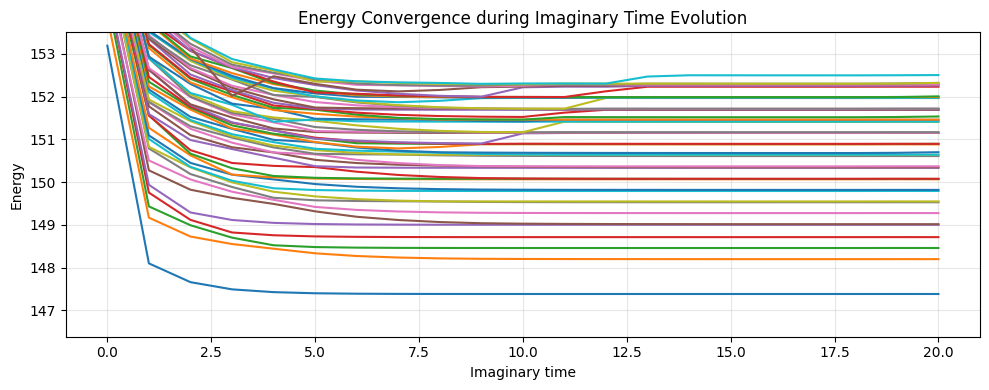

Final energy: [147.38132 148.19705 148.45752 148.71207 149.0015  149.0142  149.27487
 149.52812 149.54738 149.79192 149.81735 150.06595 150.07251 150.07797
 150.33414 150.34557 150.36975 150.60957 150.63452 150.64145 150.69974
 150.88223 150.89467 150.89539 151.14996 151.15033 151.15518 151.16805
 151.40804 151.41418 151.45752 151.46114 151.5357  151.69234 151.69295
 151.70015 151.718   151.71901 151.96771 151.96826 151.98926 151.99052
 152.00667 152.23192 152.25928 152.27487 152.28006 152.32045 152.32144
 152.50494]
Final transition energies: [0.81573486 1.0762024  1.3307495  1.6201782  1.6328888  1.8935547
 2.1468048  2.1660614  2.4105988  2.4360352  2.6846313  2.6911926
 2.6966553  2.9528198  2.9642487  2.9884338  3.2282562  3.2532043
 3.2601318  3.3184204  3.5009155  3.5133514  3.5140686  3.7686462
 3.7690125  3.7738647  3.786728   4.026718   4.0328674  4.0762024
 4.0798187  4.1543884  4.31102    4.3116302  4.3188324  4.336685
 4.3376923  4.5863953  4.5869446  4.6079407  4.609207  

In [100]:
# Calculate energies at each time step
energies = [mctdhf.calculate_energy(t, y) for t, y in zip(ts, ys)]
energies = np.array(energies)

# Plot energy convergence
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ts, np.real(energies))
ax.set_xlabel('Imaginary time')
ax.set_ylabel('Energy')
ax.set_title('Energy Convergence during Imaginary Time Evolution')
ax.grid(True, alpha=0.3)

plt.ylim(energies[-1,0]-1, energies[-1,-1]+1)

plt.tight_layout()
plt.show()

print(f"Final energy: {np.real(energies[-1])}")
print(f"Final transition energies: {np.real(energies[-1, 1:] - energies[-1,0])}")

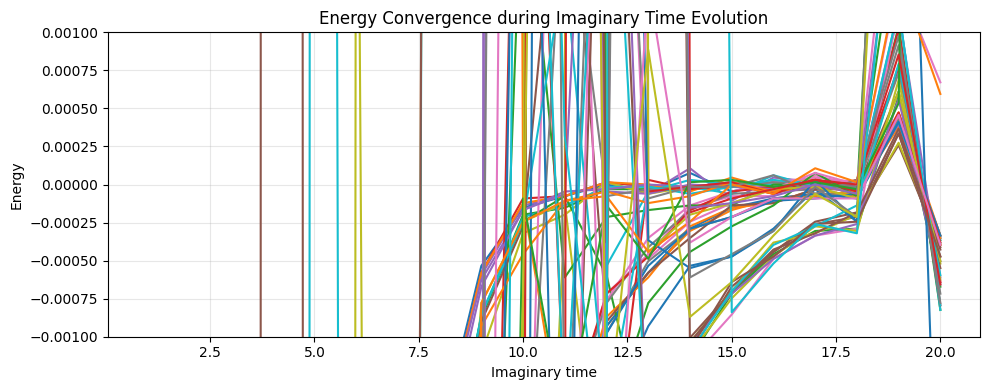

In [101]:
# Plot energy convergence
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ts[1:], np.diff(np.real(energies), axis=0))
ax.set_xlabel('Imaginary time')
ax.set_ylabel('Energy')
ax.set_title('Energy Convergence during Imaginary Time Evolution')
ax.grid(True, alpha=0.3)

plt.ylim(-1e-3, 1e-3)

plt.tight_layout()
plt.show()

In [102]:
# Extract final state.
# Rotate into the natural-orbital gauge first so the state-averaged 1-RDMs are
# diagonal per species and the CI tensor is as sparse as possible. This is an
# exact gauge transform — energies and densities are unchanged — and it gives
# the subsequent Jacobi localization a cleaner starting point.
y_no = mctdhf.rotate_to_natural_orbitals(ys[-1])
y_final, y_char, loc_groups = mctdhf.localize_states(y_no, verbose=True, energy_tol=1.5e-3)
C_final, bs_final = mctdhf._y_to_Cb(y_final)

# Build state -> group index mapping for plotting
state_to_group = {}
for g_idx, group in enumerate(loc_groups):
    for s in group:
        state_to_group[s] = g_idx

# Get SPFs for density calculation
spf_list = [jnp.array(dvr.get_spf()) for dvr in dvr_bases]

# Calculate particle densities
densities = mctdhf.calculate_particle_densities(C_final, bs_final, spf_list)

  State energies: ['147.381256', '148.197021', '148.457474', '148.712051', '149.001511', '149.014175', '149.274811', '149.528076', '149.547318', '149.791840', '149.817352', '150.065887', '150.072449', '150.077972', '150.334137', '150.345490', '150.369720', '150.609543', '150.634491', '150.641418', '150.699615', '150.882172', '150.894577', '150.895325', '151.149933', '151.150330', '151.155151', '151.168060', '151.407990', '151.414169', '151.457504', '151.461090', '151.535583', '151.692322', '151.692947', '151.700089', '151.717957', '151.718979', '151.967697', '151.968216', '151.989243', '151.990540', '152.006546', '152.231934', '152.259216', '152.274857', '152.279999', '152.320374', '152.321411', '152.504913']
  Group 0: states [0], E ≈ 147.381256, size=1
  Group 1: states [1], E ≈ 148.197021, size=1
  Group 2: states [2], E ≈ 148.457474, size=1
  Group 3: states [3], E ≈ 148.712051, size=1
  Group 4: states [4], E ≈ 149.001511, size=1
  Group 5: states [5], E ≈ 149.014175, size=1
  Gro

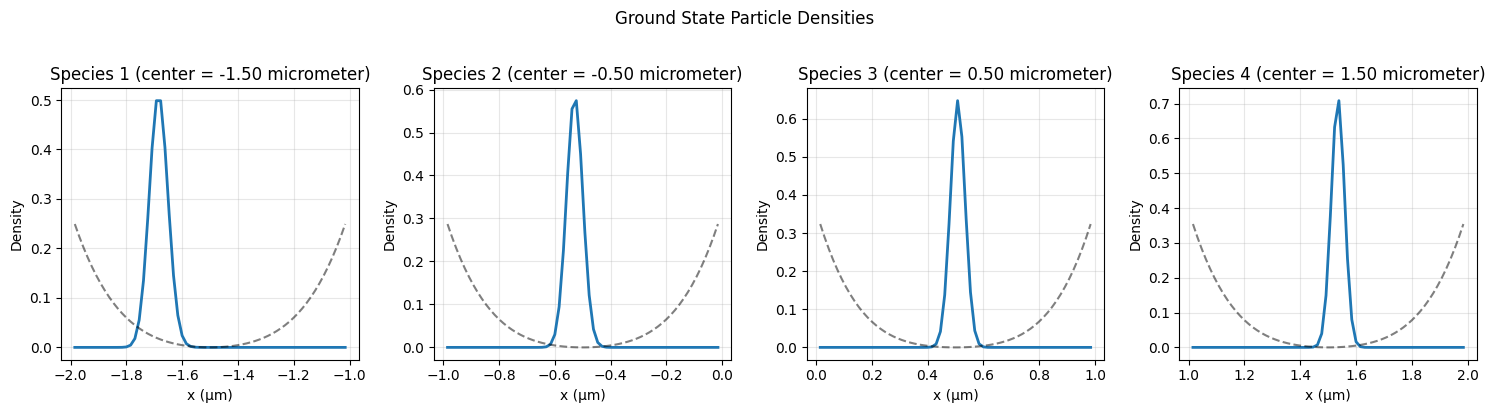

In [103]:
# Plot final densities
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for i, (dvr, density, center) in enumerate(zip(dvr_bases, densities, well_centers)):
    ax = axes[i]
    grid = dvr.get_grid()
    grid_mum = grid * length_unit.to(ureg.mum).magnitude
    rho = np.real(np.array(density[0]))  # First state
    
    # Plot density
    ax.plot(grid_mum, rho.T, linewidth=2)
    ax.fill_between(grid_mum, 0, rho[0], alpha=0.3)
    ax.fill_between(grid_mum, 0, rho[1], alpha=0.3)
    
    # Plot potential (scaled for visibility)
    pot = potentials[i](grid)
    ax.plot(grid_mum, pot / pot.max() * rho.max() * 0.5, 'k--', alpha=0.5, label='V(x) (scaled)')
    
    ax.set_xlabel('x (µm)')
    ax.set_ylabel('Density')
    ax.set_title(f'Species {i+1} (center = {center*length_unit.to(ureg.mum):.2f})')
    ax.grid(True, alpha=0.3)

plt.suptitle('Ground State Particle Densities', y=1.02)
plt.tight_layout()
plt.show()



In [104]:
# Plot all densities with coefficient table to the right
fig, axs = plt.subplots(num_states, 1, figsize=(16, 4*num_states), sharex=True)
fig.subplots_adjust(right=0.6)

F = qubit_corner_fidelities(C_final, num_wells, 2)
matched_idx, fidelities, loss = match_configs(F)
state_labels = iter_bitstrings(num_wells, 2)

for n in range(num_states):
    coeff_text = format_coefficient_table(C_final, n, 1e-1)

    for i, (dvr, density) in enumerate(zip(dvr_bases, densities)):
        grid = dvr.get_grid()
        rho = np.real(np.array(density[n]))
        axs[n].plot(grid, rho, color=f"C{i}", linewidth=2, label=f'Species {i+1}')
        axs[n].fill_between(grid, 0, rho, color=f"C{i}", alpha=0.2)

    axs[n].set_ylabel('Density')

    title = f"State {n} (group {state_to_group[n]}), Energy = {np.real(energies[-1,n]):.3f}"
    if n in matched_idx:
        ind = np.where(matched_idx == n)[0][0]
        title += f", State = {state_labels[ind]}, Fidelity = {fidelities[ind]:.4f}"

    axs[n].set_title(title)
    axs[n].grid(True, alpha=0.3)
    #axs[n].legend(loc='upper left', bbox_to_anchor=(1, 0.9))
    axs[n].text(1.02, 0.98, coeff_text, transform=axs[n].transAxes, fontsize=8, fontfamily='monospace',
                verticalalignment='top', horizontalalignment='left',
                bbox=dict(boxstyle='round,pad=0.5', facecolor='wheat', alpha=0.5))


axs[-1].set_xlabel('x')
plt.tight_layout(rect=[0, 0, 0.6, 1])
plt.show()


# Qubit-like parameter optimization

Pick (α, β) per well so that the lowest 16 many-body eigenstates of the coupled MCTDHF Hamiltonian are clean Hartree products of a 4-qubit basis |n₁n₂n₃n₄⟩, n_s ∈ {0, 1}.

The pipeline below mirrors `test/optimize_qubit_params.py` but is inlined for inspection. Steps:

1. **Evaluator** — given (α, β) in GHz, run state-averaged ITE with 50 states, Rayleigh–Ritz post-diagonalise to get true eigenstates of H on the converged subspace, build a qubit target basis from the natural orbitals of the state-averaged 1-RDM over the lowest 16 eigenstates, and compute the fidelity matrix + Hungarian-matched loss.
2. **Sanity check** — call the evaluator at the physical starting point and inspect the matched ladder.
3. **Nelder–Mead** — scipy on the 8-vector [α₀..α₃, β₀..β₃] (GHz), warm-starting each ITE from the previous converged state.
4. **Inspect best** — re-evaluate at (α*, β*) and plot.

## Step 1 — One-shot evaluator: ITE → Rayleigh–Ritz → fidelity

`evaluate_params(α, β)` is the inner loop the optimiser will call. Pipeline:

1. Build per-well DVR Hamiltonians from `anharm_pot` at the requested (α, β).
2. Construct an `MCTDHF_n_species_DVR` solver with `imag_time=True` and `num_states=50` (need ≥36 to reach |1111⟩, plus headroom for non-qubit "intruder" eigenstates in the same energy band — these are doubly-/triply-/quadruply-excited-in-one-well configurations that legitimately live below |1111⟩).
3. Propagate via the half-step CMF integrator with SIL sub-propagators. State-averaged ITE drives the 50 states to span the lowest-50-energy subspace of H projected onto the orbital span.
4. **Rayleigh–Ritz**: state-averaged ITE only converges the *subspace*, not the individual eigenbasis within it. Build `H_{IJ} = ⟨Ψ_I|H|Ψ_J⟩` on the converged subspace, solve the generalised eigenproblem against `S_{IJ} = ⟨Ψ_I|Ψ_J⟩`, and rotate the CI tensor accordingly. Orbitals are unchanged.
5. **Qubit target basis**: average the 1-RDMs over the 16 lowest eigenstates per species, eigh, take the two leading natural orbitals as `|0⟩_s, |1⟩_s`. (Bare-well eigenstates are the wrong target: with KAPPA ≈ 811 the MCTDHF orbitals are heavily Coulomb-dressed, and `|⟨v_bare|b_MCTDHF⟩|² ≈ 0.4–0.5` per species would break the Hartree-product factorisation.)
6. Compute `F[k, n] = |⟨n₁n₂n₃n₄|Ψ_k⟩|²` and use Hungarian matching to assign each of the 16 configs to a distinct eigenstate. Loss = 16 − Σ_n F.

In [15]:
from utils import *
from optimize_qubit_params import *
from optimize_qubit_params import _ghz_to_dimensionless, _build_h_list, _rayleigh_ritz

# ── Step 1 code: define the evaluator (ITE → RR → fidelity) ───────────────────

# Reuse the geometry built in earlier cells: dvr_bases, g_dict, well_centers,
# typical_freq, anharm_pot, num_wells, num_dvr.


print(iter_bitstrings(4, 2))

[(0, 0, 0, 0), (1, 0, 0, 0), (0, 1, 0, 0), (0, 0, 1, 0), (0, 0, 0, 1), (1, 1, 0, 0), (1, 0, 1, 0), (1, 0, 0, 1), (0, 1, 1, 0), (0, 1, 0, 1), (0, 0, 1, 1), (1, 1, 1, 0), (1, 1, 0, 1), (1, 0, 1, 1), (0, 1, 1, 1), (1, 1, 1, 1)]


## Step 2 — Sanity check at the physical starting point

α=[7, 8, 9, 10] GHz gives single-excitation detunings ~1 GHz between adjacent wells (well above inter-well Coulomb J at 1 μm separation). β=0.15 GHz makes each well's |2⟩-anharmonicity comparable to J, so doubly-excited states stay split off from the qubit subspace. Expectation: |0000⟩ → state 0 with F ≈ 1, single excitations match low-lying states, higher excitations progressively more hybridised.

In [54]:
num_states = 50
num_steps = 500

alphas = _ghz_to_dimensionless([7., 8., 9., 10.])    # GHz — single-excitation detunings ~1 GHz
betas  = _ghz_to_dimensionless([0.2] * num_wells)   # GHz — anharmonicity comparable to inter-well J at ~1 µm

h_list = _build_h_list(alphas, betas)

mctdhf = MCTDHF_n_species_DVR(
    h_list=h_list,
    g_dict=G_DICT,
    num_particles=[1] * NUM_WELLS,
    num_mctdhf_orbitals=[NUM_MCTDHF_ORBITALS] * NUM_WELLS,
    num_spatial_orbitals=[NUM_DVR] * NUM_WELLS,
    num_states=num_states,
    imag_time=True,
    state_weights=np.concatenate([np.ones(1), 0.5*np.ones(4), np.zeros(num_states-5)])
)

integrator = get_cmf_integrator(
    mctdhf, dt=1e-1, c_propagator="diagonalize", b_propagator="sil"
    )


ts, ys = mctdhf.integrate(
    integrator=integrator,
    num_steps=num_steps,
    t_init=0.0,
    normalize=True,
    noise_bs=0,
    noise_C=1e-3,
    save_every=1,
)

Species 0: lowest eigenvalues = [0.35484475 1.073819   1.8107493  2.5645046 ]
Species 1: lowest eigenvalues = [0.4048632 1.2239544 2.061222  2.9156368]
Species 2: lowest eigenvalues = [0.45487747 1.3740617  2.3115995  3.2665474 ]
Species 3: lowest eigenvalues = [0.50488937 1.5241492  2.5619085  3.6172957 ]


In [ ]:
C_prev, bs_prev = mctdhf._y_to_Cb(y_final)

In [46]:
alphas_new = alphas + _ghz_to_dimensionless(np.array([1, 0.2, 0.2, -2]))
h_list_new = _build_h_list(alphas_new, betas)

mctdhf = MCTDHF_n_species_DVR(
    h_list=h_list_new,
    g_dict=G_DICT,
    num_particles=[1] * NUM_WELLS,
    num_mctdhf_orbitals=[NUM_MCTDHF_ORBITALS] * NUM_WELLS,
    num_spatial_orbitals=[NUM_DVR] * NUM_WELLS,
    num_states=10,
    imag_time=True,
)

integrator = get_cmf_integrator(
    mctdhf, dt, c_propagator="diagonalize", b_propagator="sil"
    )



In [47]:
ts, ys = mctdhf.integrate(
    integrator=integrator,
    num_steps=100,
    t_init=0.0,
    bs_init_list=bs_prev,
    C_init=C_prev,
    normalize=True,
    noise_bs=0.0,
    noise_C=0.0,
    save_every=1,
)

In [16]:
y_final = ys[-1]
C_final, bs_final = mctdhf._y_to_Cb(y_final)

In [17]:
energies = np.array([mctdhf.calculate_energy(t, y) for t, y in zip(ts, ys)])
E = energies[-1]

C_rr, E_rr = _rayleigh_ritz(mctdhf, C_final, bs_final, t=ts[-1])

In [18]:
print(E-E_rr) 

[ 6.1035156e-05+0.j -4.5776367e-05+0.j -3.0517578e-05+0.j
 -6.1035156e-05+0.j -3.0517578e-05+0.j  4.5776367e-05+0.j
  3.0517578e-05+0.j -4.5776367e-05+0.j  1.5258789e-05+0.j
 -6.1035156e-05+0.j -3.0517578e-05+0.j -3.0517578e-05+0.j
  3.0517578e-05+0.j -4.5776367e-05+0.j -3.0517578e-05+0.j
  4.5776367e-05+0.j -6.1035156e-05+0.j  0.0000000e+00+0.j
  1.5258789e-05+0.j -1.5258789e-05+0.j -6.1035156e-05+0.j
  0.0000000e+00+0.j -3.0517578e-05+0.j  3.0517578e-05+0.j
 -1.5258789e-05+0.j  6.1035156e-05+0.j -4.5776367e-05+0.j
 -4.5776367e-05+0.j  0.0000000e+00+0.j -6.1035156e-05+0.j
  1.5258789e-05+0.j -1.5258789e-05+0.j  1.5258789e-05+0.j
 -9.1552734e-05+0.j  1.5258789e-05+0.j -1.2207031e-04+0.j
  1.5258789e-05+0.j -6.1035156e-05+0.j  0.0000000e+00+0.j
  7.6293945e-05+0.j  1.5258789e-05+0.j -3.0517578e-05+0.j
  1.5258789e-05+0.j  0.0000000e+00+0.j -3.0517578e-05+0.j
  1.5258789e-05+0.j -1.0681152e-04+0.j  1.5258789e-05+0.j
 -7.6293945e-05+0.j  0.0000000e+00+0.j]


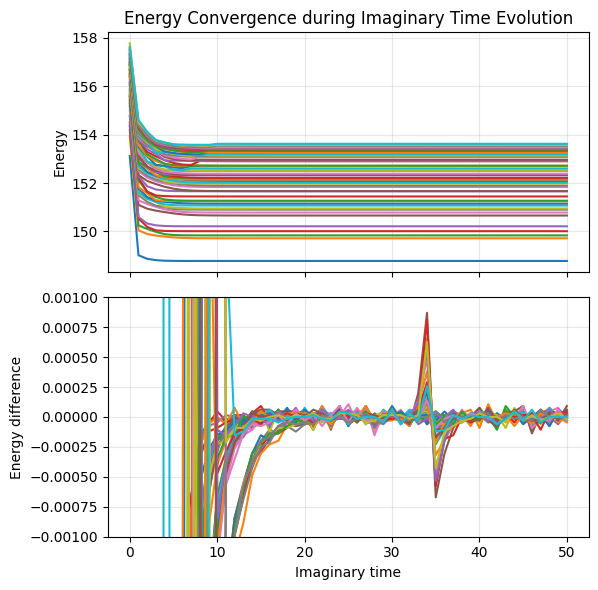

In [19]:
# Plot energy convergence
fig, ax = plt.subplots(2,1, figsize=(6, 6), sharex=True)
ax[0].plot(ts, np.real(energies))
#ax[0].set_xlabel('Imaginary time')
ax[0].set_ylabel('Energy')
ax[0].set_title('Energy Convergence during Imaginary Time Evolution')
ax[0].grid(True, alpha=0.3)

ax[1].plot(ts[1:], np.diff(np.real(energies), axis=0))
ax[1].set_xlabel('Imaginary time')
ax[1].set_ylabel('Energy difference')
ax[1].grid(True, alpha=0.3)

plt.ylim(-1e-3, 1e-3)

plt.tight_layout()
plt.show()

In [20]:
y_final = mctdhf.rotate_to_natural_orbitals(y_final)
C_final, bs_final = mctdhf._y_to_Cb(y_final)
F = qubit_corner_fidelities(C_final, 4, 2)
matched_idx, fidelities, loss = match_configs(F)

In [25]:
np.round(F, 2).shape

(50, 16)

In [23]:
matched_idx

array([ 0,  1,  2,  3,  4,  5,  8, 10,  9, 12, 13, 19, 20, 26, 27, 45])

In [ ]:
# ── Step 2 code: sanity check at the physical starting point ──────────────────

alphas_start = [7., 8., 9., 10.]    # GHz — single-excitation detunings ~1 GHz
betas_start  = [0.15] * num_wells   # GHz — anharmonicity comparable to inter-well J at ~1 µm

res0 = evaluate_params(alphas_start, betas_start, num_steps=2000)

print(f"loss = {res0['loss']:.4f}    min fidelity = {res0['fidelities'].min():.4f}")
print(f"lowest 16 eigenvalues: {np.round(res0['energies'][:16], 4)}")
print()
for cfg, f, idx in zip(CONFIGS, res0['fidelities'], res0['matched_idx']):
    print(f"  {cfg} -> eigenstate {idx:2d}, F = {f:.4f}, E = {res0['energies'][idx]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={'width_ratios': [1, 2]})
plot_qubit_ladder(res0['energies'], res0['matched_idx'], CONFIGS,
                  ax=axes[0], title='Energy ladder')
plot_fidelity_bars(res0['fidelities'], CONFIGS,
                   ax=axes[1], title='Matched fidelities at start')
plt.tight_layout()
plt.show()

## Step 3 — Nelder–Mead with warm-starting

scipy Nelder–Mead on the 8-vector `[α₀..α₃, β₀..β₃]` (GHz). Bounds `α ∈ [5, 15]`, `β ∈ [0.02, 0.4]` are enforced via a quadratic penalty (no inner ITE on out-of-bounds proposals — the penalty alone steers the simplex back).

**Warm-start.** Between adjacent evaluations the change in (α, β) is small, so the previous converged 50-state manifold is a much better initial guess than the default single-particle product state. The first call runs cold (`num_steps=2000`, plus `noise_C=1e-3`); subsequent calls reuse `y_final` from the prior eval and run with `num_steps=500`.

Wall time: ~1–2 hours total. Each cold ITE takes ~tens of seconds; each warm one is ~4× faster.

In [ ]:
# ── Step 3 code: Nelder-Mead with warm-starting ───────────────────────────────

from scipy.optimize import minimize
import time

ALPHA_BOUNDS = (5.0, 15.0)
BETA_BOUNDS  = (0.02, 0.4)
PENALTY      = 1e3   # quadratic penalty coefficient outside bounds


def out_of_bounds_penalty(x):
    """Quadratic penalty so Nelder-Mead steers back inside the box."""
    pen = 0.0
    for a in x[:num_wells]:
        pen += PENALTY * max(0., ALPHA_BOUNDS[0] - a)**2
        pen += PENALTY * max(0., a - ALPHA_BOUNDS[1])**2
    for b in x[num_wells:]:
        pen += PENALTY * max(0., BETA_BOUNDS[0] - b)**2
        pen += PENALTY * max(0., b - BETA_BOUNDS[1])**2
    return pen


x0 = np.array([7., 8., 9., 10., 0.15, 0.15, 0.15, 0.15])

# Closure state: rolling y_prev (warm-start), best-so-far, full trajectory.
opt_state = dict(y_prev=None, best_loss=np.inf, best_x=None, best_result=None,
                 traj=[], i=0)


def loss_fn(x):
    """scipy callback: penalty if OOB, else evaluate_params with warm-start."""
    opt_state["i"] += 1
    pen = out_of_bounds_penalty(x)
    if pen > 0:
        opt_state["traj"].append(dict(x=x.copy(), loss=pen, oob=True))
        print(f"[{opt_state['i']:03d}] OOB  penalty={pen:.2f}")
        return pen

    n_steps = 2000 if opt_state["y_prev"] is None else 500
    t0 = time.time()
    r = evaluate_params(x[:num_wells], x[num_wells:],
                        y_prev=opt_state["y_prev"], num_steps=n_steps)
    wall = time.time() - t0

    print(f"[{opt_state['i']:03d}] α={np.round(x[:4], 3)}  β={np.round(x[4:], 3)}  "
          f"loss={r['loss']:.4f}  min_fid={r['fidelities'].min():.3f}  {wall:.1f}s")

    opt_state["y_prev"] = r["y_final"]                  # warm-start next call
    if r["loss"] < opt_state["best_loss"]:
        opt_state["best_loss"] = r["loss"]
        opt_state["best_x"]    = x.copy()
        opt_state["best_result"] = r
    opt_state["traj"].append(dict(x=x.copy(), loss=r["loss"],
                                   min_fid=float(r["fidelities"].min()), oob=False))
    return r["loss"]


res = minimize(loss_fn, x0, method='Nelder-Mead',
               options=dict(xatol=1e-3, fatol=5e-3, maxiter=200, disp=True))

alpha_star = opt_state["best_x"][:num_wells]
beta_star  = opt_state["best_x"][num_wells:]
print(f"\nBest α (GHz) = {alpha_star}")
print(f"Best β (GHz) = {beta_star}")
print(f"Best loss    = {opt_state['best_loss']:.4f}")

# Plot loss + worst-fidelity trajectories.
losses_all = [t["loss"] for t in opt_state["traj"]]
min_fids   = [t["min_fid"] for t in opt_state["traj"] if not t["oob"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(losses_all, 'o-', ms=3); axes[0].set_yscale('log')
axes[0].set_xlabel('evaluation'); axes[0].set_ylabel('loss')
axes[0].grid(True, alpha=0.3); axes[0].set_title('Loss vs evaluation')
axes[1].plot(min_fids, 'o-', ms=3)
axes[1].set_xlabel('in-bounds eval'); axes[1].set_ylabel('min fidelity')
axes[1].grid(True, alpha=0.3); axes[1].set_title('Worst-config fidelity vs evaluation')
plt.tight_layout()
plt.show()

## Step 4 — Inspect the best parameters

Run a fresh cold ITE at (α*, β*) (the warm-start state from the optimiser is correlated with all the intermediate evaluations and not a clean baseline). Print per-config matched eigenstates and plot.

In [ ]:
# ── Step 4 code: re-evaluate at the optimum and plot ──────────────────────────

res_best = evaluate_params(alpha_star, beta_star, num_steps=2000)

print(f"loss = {res_best['loss']:.4f}    min fidelity = {res_best['fidelities'].min():.4f}")
worst = int(np.argmin(res_best['fidelities']))
print(f"worst config: {CONFIGS[worst]}, F = {res_best['fidelities'][worst]:.4f}")
print()
for cfg, f, idx in zip(CONFIGS, res_best['fidelities'], res_best['matched_idx']):
    print(f"  {cfg} -> eigenstate {idx:2d}, F = {f:.4f}, E = {res_best['energies'][idx]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={'width_ratios': [1, 2]})
plot_qubit_ladder(res_best['energies'], res_best['matched_idx'], CONFIGS,
                  ax=axes[0], title='Energy ladder at (α*, β*)')
plot_fidelity_bars(res_best['fidelities'], CONFIGS,
                   ax=axes[1], title='Matched fidelities at (α*, β*)')
plt.tight_layout()
plt.show()